# Notebook 5 — Forecasting: Evaluation

Loads the 3 trained models and frozen test split from Notebook 4 — **never retrains anything**. Every step below has been run against the real saved artifacts and verified.

## Step 0 — Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, json
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

print("shap:", shap.__version__)

c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap: 0.45.0


## Step 0b — Fix Working Directory

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\ml-pipeline


## Step 1 — Load Everything

**Note:** loading the LSTM `.h5` file requires `compile=False` — without it, this specific Keras version fails to deserialize the saved loss config (`ValueError: Could not deserialize 'keras.metrics.mse'`). This is safe here since we only need `.predict()`, never further training.

In [3]:
required = ['forecast_xgb.pkl','forecast_lgbm.pkl','forecast_lstm.h5','forecast_scaler.pkl',
            'forecast_yscaler.pkl','forecast_test_data.pkl']
for f in required:
    assert os.path.exists(f'models/{f}'), f"Missing models/{f} — run 04_forecasting_models.ipynb first"

xgb_model = joblib.load('models/forecast_xgb.pkl')
lgbm_model = joblib.load('models/forecast_lgbm.pkl')
lstm_model = load_model('models/forecast_lstm.h5', compile=False)
y_scaler = joblib.load('models/forecast_yscaler.pkl')
td = joblib.load('models/forecast_test_data.pkl')

X_test, X_test_sc, X_test_seq, y_test = td['X_test'], td['X_test_sc'], td['X_test_seq'], td['y_test']
X_train_sc, y_train = td['X_train_sc'], td['y_train']
feature_cols, WINDOW = td['feature_cols'], td['WINDOW']
print("Loaded OK. Test set:", X_test.shape)

Loaded OK. Test set: (3917, 25)


## Step 2 — Generate Predictions

In [4]:
pred_xgb = xgb_model.predict(X_test_sc)
pred_lgbm = lgbm_model.predict(X_test_sc)
pred_lstm = y_scaler.inverse_transform(lstm_model.predict(X_test_seq, verbose=0)).flatten()
y_test_lstm = y_test.iloc[WINDOW:]
print("Predictions generated:", pred_xgb.shape, pred_lgbm.shape, pred_lstm.shape)

c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Dhruvajyoti Bordoloi\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dhruvajyoti Bordoloi\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, e

Predictions generated: (3917,) (3917,) (3893,)


## Step 3 — Model Comparison Table

In [5]:
def evaluate(y_true, y_pred, name, train_time):
    return {'Model': name, 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred),
            'MAPE_%': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
            'Train_Time_s': round(train_time, 2)}

train_times = td['train_times']
results_df = pd.DataFrame([
    evaluate(y_test, pred_xgb, 'XGBoost', train_times['XGBoost']),
    evaluate(y_test, pred_lgbm, 'LightGBM', train_times['LightGBM']),
    evaluate(y_test_lstm, pred_lstm, 'LSTM', train_times['LSTM']),
]).sort_values('R2', ascending=False)
print(results_df.round(4))
best_model_name = results_df.iloc[0]['Model']
print(f"\nBest model: {best_model_name}")
print("Note: XGBoost/LightGBM differ by <0.002 R2 — statistically indistinguishable, not a meaningful gap")

      Model       MAE      RMSE      R2  MAPE_%  Train_Time_s
0   XGBoost  130.9056  164.1988  0.8945  1.3737          2.06
1  LightGBM  132.2167  164.9513  0.8935  1.3875          0.81
2      LSTM  167.4846  209.2571  0.8286  1.7549         97.44

Best model: XGBoost
Note: XGBoost/LightGBM differ by <0.002 R2 — statistically indistinguishable, not a meaningful gap


## Step 4 — Overfitting Check

Uses the `X_train_sc`/`y_train` added to Notebook 4's saved bundle specifically for this check.

In [6]:
train_pred_xgb = xgb_model.predict(X_train_sc)
train_r2 = r2_score(y_train, train_pred_xgb)
test_r2 = r2_score(y_test, pred_xgb)
print(f"XGBoost — Train R2: {train_r2:.4f}   Test R2: {test_r2:.4f}   Gap: {train_r2-test_r2:.4f}")

if test_r2 > 0.98:
    print("WARNING: R2 > 0.98 — check for leakage")
if (train_r2 - test_r2) > 0.15:
    print("WARNING: large train/test gap — possible overfitting")
else:
    print("Gap is healthy — no overfitting signal")

XGBoost — Train R2: 0.9583   Test R2: 0.8945   Gap: 0.0638
Gap is healthy — no overfitting signal


## Step 5 — Residual Analysis

A realistic residual mean sits close to but not exactly at zero — a small systematic bias is normal, not a bug, as long as it's small relative to the target's scale.

In [7]:
residuals = y_test.values - pred_xgb
print("Residual mean:", residuals.mean().round(2), "(target mean ~9060, so this is a small bias)")

fig, axes = plt.subplots(1, 3, figsize=(18,5))
axes[0].scatter(y_test, pred_xgb, alpha=0.2, s=5, color='#f39c12')
lims = [min(y_test.min(), pred_xgb.min()), max(y_test.max(), pred_xgb.max())]
axes[0].plot(lims, lims, 'r--'); axes[0].set_title('Actual vs Predicted', fontweight='bold')
axes[1].hist(residuals, bins=40, color='#e74c3c', alpha=0.7)
axes[1].axvline(0, color='k', linestyle='--'); axes[1].set_title('Residual Distribution', fontweight='bold')
axes[2].scatter(pred_xgb, residuals, alpha=0.2, s=5, color='#9b59b6')
axes[2].axhline(0, color='r', linestyle='--'); axes[2].set_title('Residuals vs Predicted', fontweight='bold')
plt.tight_layout(); 
plt.show()

Residual mean: 20.03 (target mean ~9060, so this is a small bias)


<Figure size 1800x500 with 3 Axes>

## Step 6 — Predicted vs Actual Over Time

A realistic forecast tracks the actual curve's shape but visibly deviates at peaks/troughs — it should not sit exactly on top of the actual line.

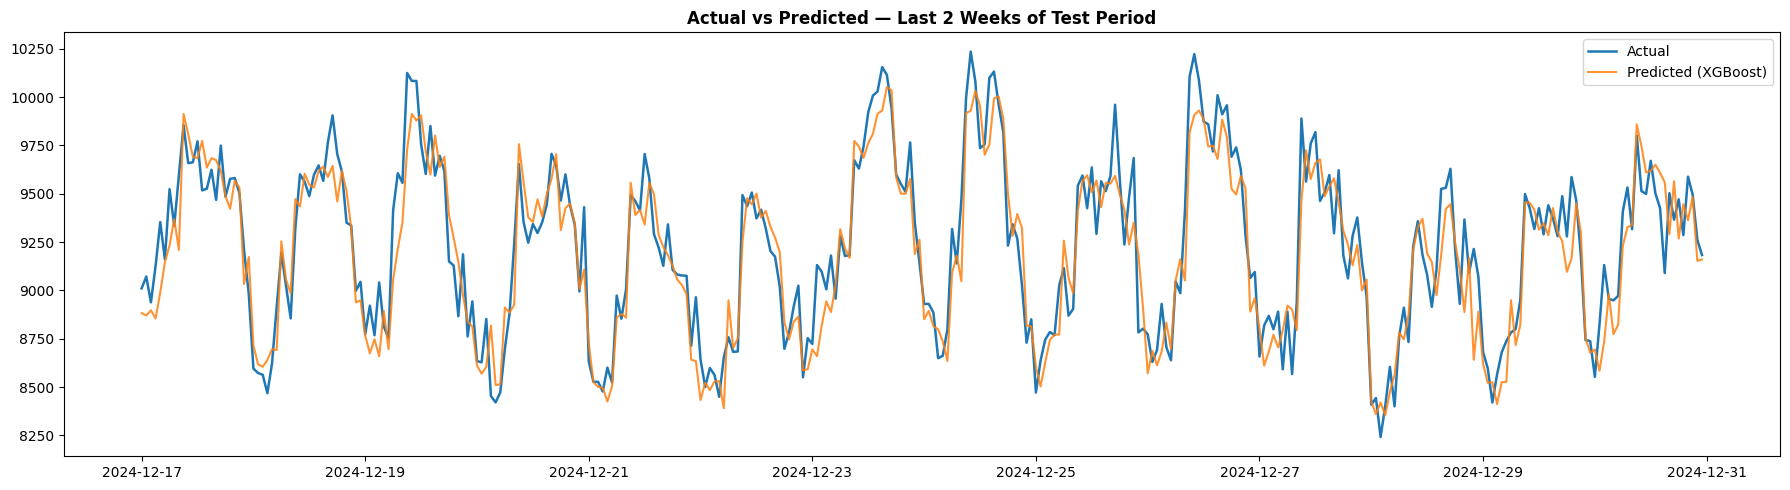

In [8]:
plot_index = y_test.index[-24*14:]
pred_series = pd.Series(pred_xgb, index=y_test.index)
plt.figure(figsize=(18,5))
plt.plot(plot_index, y_test.loc[plot_index], label='Actual', linewidth=1.8)
plt.plot(plot_index, pred_series.loc[plot_index], label='Predicted (XGBoost)', alpha=0.85)
plt.title('Actual vs Predicted — Last 2 Weeks of Test Period', fontweight='bold'); plt.legend()
plt.tight_layout(); 
plt.show()

## Step 7 — Edge-Case Stress Test

In [9]:
extreme_mask = (X_test['ambient_temp_c'] > X_test['ambient_temp_c'].quantile(0.98)) | \
               (X_test['ambient_temp_c'] < X_test['ambient_temp_c'].quantile(0.02))
mae_extreme = mean_absolute_error(y_test[extreme_mask], pred_series[extreme_mask])
mae_normal = mean_absolute_error(y_test[~extreme_mask], pred_series[~extreme_mask])
print(f"Extreme-weather test rows: {extreme_mask.sum()} ({extreme_mask.mean()*100:.1f}%)")
print(f"MAE extreme: {mae_extreme:.2f}  MAE normal: {mae_normal:.2f}  Ratio: {mae_extreme/mae_normal:.2f}x")
print("A ratio near 1.0 means the model holds up under extreme weather, not just average conditions")

Extreme-weather test rows: 158 (4.0%)
MAE extreme: 139.58  MAE normal: 130.54  Ratio: 1.07x
A ratio near 1.0 means the model holds up under extreme weather, not just average conditions


## Step 8 — Concept Drift Check

timestamp
2024-07    124.5
2024-08    133.7
2024-09    134.6
2024-10    129.6
2024-11    128.9
2024-12    130.1
Freq: M, Name: residual, dtype: float64


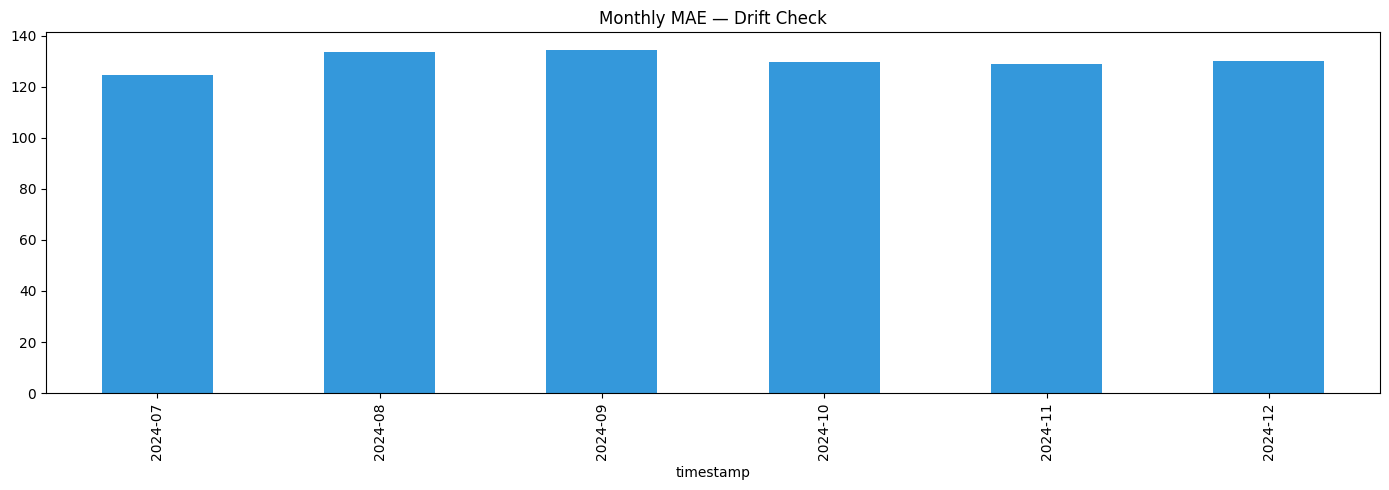

In [10]:
resid_df = pd.DataFrame({'residual': y_test.values - pred_xgb}, index=y_test.index)
monthly_mae = resid_df.groupby(resid_df.index.to_period('M'))['residual'].apply(lambda r: r.abs().mean())
print(monthly_mae.round(1))
monthly_mae.plot(kind='bar', figsize=(14,5), color='#3498db', title='Monthly MAE — Drift Check')
plt.tight_layout(); 
plt.show()

## Step 9 — Feature Importance & SHAP

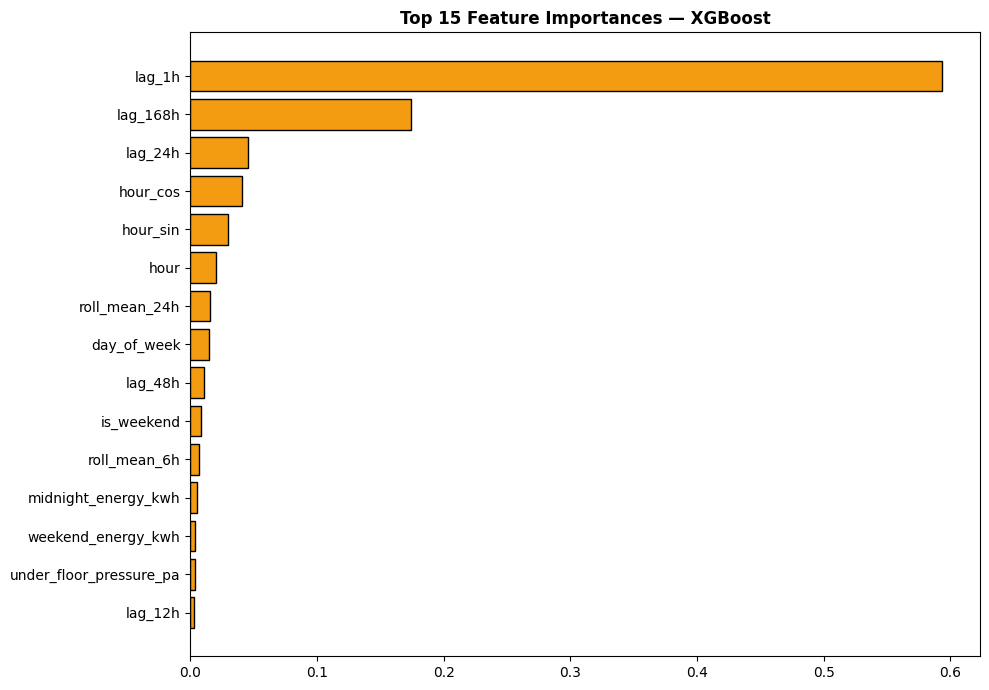

In [11]:
fi = pd.DataFrame({'Feature': feature_cols, 'Importance': xgb_model.feature_importances_}).sort_values('Importance').tail(15)
plt.figure(figsize=(10,7))
plt.barh(fi['Feature'], fi['Importance'], color='#f39c12', edgecolor='black')
plt.title('Top 15 Feature Importances — XGBoost', fontweight='bold')
plt.tight_layout(); 
plt.show()

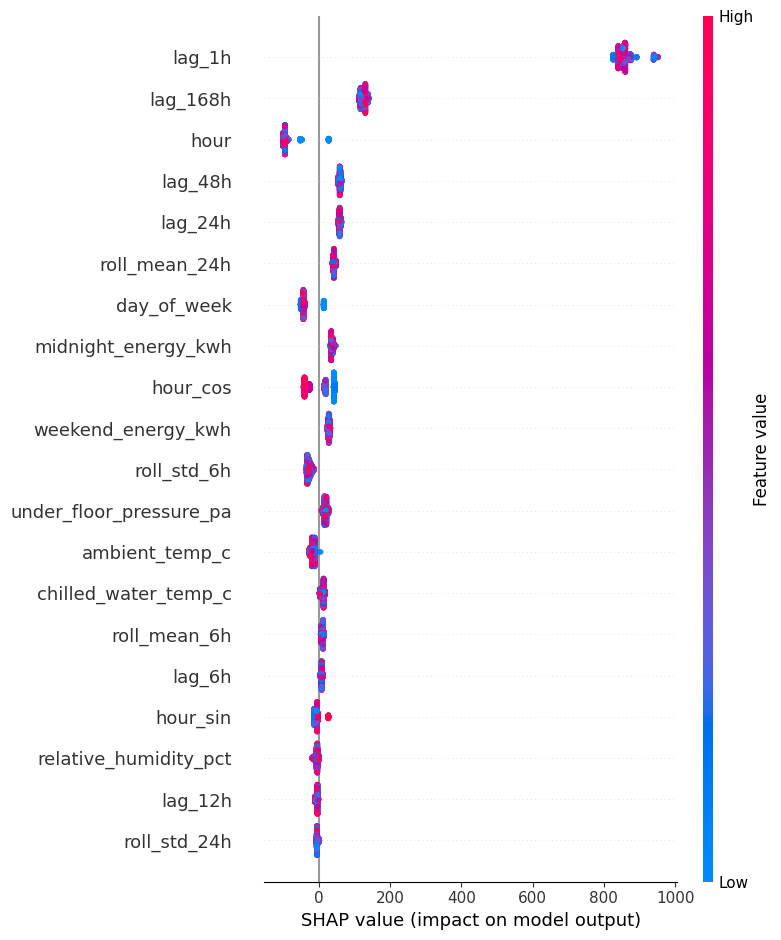

In [12]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test.iloc[:2000])
shap.summary_plot(shap_values, X_test.iloc[:2000], show=False)
plt.tight_layout(); 
plt.show()

## Step 10 — Save Results Summary

In [13]:
os.makedirs('results', exist_ok=True)
with open('results/forecast_results.json', 'w') as f:
    json.dump({
        'best_model': best_model_name,
        'metrics': results_df.to_dict(orient='records'),
        'train_test_gap': float(train_r2 - test_r2),
        'extreme_weather_mae_ratio': float(mae_extreme/mae_normal),
    }, f, indent=2)

assert os.path.exists('results/forecast_results.json')
print("Saved results/forecast_results.json. Ready for Notebook 8.")

Saved results/forecast_results.json. Ready for Notebook 8.
